In [1]:
import pandas as pd
data = pd.read_csv(r"C:\Users\Abid\Downloads\crop_yield.csv")
data.head(10)

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
5,F006,Rice,2000.0,6.0,06/01/2023,Faisalabad,Rabi,Yes,40000
6,F007,Maize,1500.0,6.0,07/01/2023,Faisalabad,Rabi,No,30000
7,F008,Wheat,1500.0,5.0,08/01/2023,Lahore,Rabi,No,30000
8,F009,Wheat,2000.0,5.0,09/01/2023,Faisalabad,Rabi,Yes,40000
9,F010,Wheat,1500.0,3.0,10/01/2023,Faisalabad,Rabi,Yes,30000


In [2]:
data.isna().sum()

FARM_ID              0
CROP_TYPE            0
YIELD_KG           330
AREA_ACRES         144
HARVEST_DATE         0
DISTRICT           126
SEASON               0
FERTILIZER_USED    318
YIELD_VALUE          0
dtype: int64

In [3]:
data.dtypes

FARM_ID                str
CROP_TYPE              str
YIELD_KG           float64
AREA_ACRES         float64
HARVEST_DATE           str
DISTRICT               str
SEASON                 str
FERTILIZER_USED        str
YIELD_VALUE          int64
dtype: object

In [4]:
data.describe()

,YIELD_KG,AREA_ACRES,YIELD_VALUE
count,2670.000000,2856.000000,3000.000000
mean,2014.232210,4.420168,39657.780000
std,407.846962,0.979259,8405.078755
min,1500.000000,3.000000,20068.000000
25%,1500.000000,4.000000,30000.000000
50%,2000.000000,4.000000,40000.000000
75%,2500.000000,5.000000,50000.000000
max,2500.000000,6.000000,50000.000000


In [5]:
data.describe(include = str)

,FARM_ID,CROP_TYPE,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED
count,3000,3000,3000,2874,3000,2682
unique,3000,4,3000,4,2,2
top,F001,Wheat,01/01/2023,Faisalabad,Rabi,Yes
freq,1,1158,1,936,1528,1776


In [6]:
worked_data = data.dropna(subset='YIELD_KG')
worked_data

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
...,...,...,...,...,...,...,...,...,...
2995,F2996,Wheat,1500.0,NaN,15/03/2031,NaN,Rabi,Yes,30000
2996,F2997,Rice,2000.0,3.0,16/03/2031,Lahore,Rabi,Yes,40000
2997,F2998,Sugarcane,2000.0,5.0,17/03/2031,Lahore,Rabi,Yes,40000
2998,F2999,Sugarcane,2000.0,NaN,18/03/2031,Lahore,Rabi,NaN,40000


In [7]:
worked_data['AREA_ACRES'] = worked_data['AREA_ACRES'].fillna(worked_data['AREA_ACRES'].mean())
worked_data

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.000000,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.000000,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.000000,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,4.412667,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.000000,05/01/2023,Faisalabad,Rabi,No,30000
...,...,...,...,...,...,...,...,...,...
2995,F2996,Wheat,1500.0,4.412667,15/03/2031,NaN,Rabi,Yes,30000
2996,F2997,Rice,2000.0,3.000000,16/03/2031,Lahore,Rabi,Yes,40000
2997,F2998,Sugarcane,2000.0,5.000000,17/03/2031,Lahore,Rabi,Yes,40000
2998,F2999,Sugarcane,2000.0,4.412667,18/03/2031,Lahore,Rabi,NaN,40000


In [8]:
worked_data['DISTRICT'] = worked_data['DISTRICT'].fillna('Unknown')
worked_data['FERTILIZER_USED'] = worked_data['FERTILIZER_USED'].fillna('No')
worked_data['YIELD_VALUE'] = worked_data['YIELD_VALUE'].fillna(worked_data['YIELD_VALUE'].mean())
worked_data['HARVEST_DATE'] = pd.to_datetime(worked_data['HARVEST_DATE'], format='%d/%m/%Y')

In [9]:
worked_data['FARM_ID'] = worked_data['FARM_ID'].str.replace('F', '').astype(int)

In [10]:
worked_data.isna().sum()

FARM_ID            0
CROP_TYPE          0
YIELD_KG           0
AREA_ACRES         0
HARVEST_DATE       0
DISTRICT           0
SEASON             0
FERTILIZER_USED    0
YIELD_VALUE        0
dtype: int64

In [11]:
worked_data.dtypes

FARM_ID                     int64
CROP_TYPE                     str
YIELD_KG                  float64
AREA_ACRES                float64
HARVEST_DATE       datetime64[us]
DISTRICT                      str
SEASON                        str
FERTILIZER_USED               str
YIELD_VALUE                 int64
dtype: object

In [12]:
bar_chart = worked_data.groupby('CROP_TYPE')['YIELD_KG'].sum()
bar_chart

CROP_TYPE
Maize        1112500.0
Rice         1638000.0
Sugarcane     592000.0
Wheat        2035500.0
Name: YIELD_KG, dtype: float64

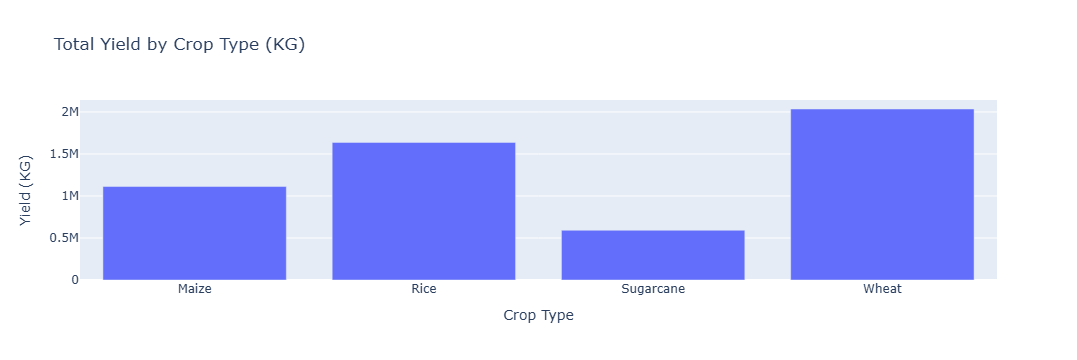

In [13]:
import plotly.express as px
fig = px.bar(
    bar_chart,
    x=bar_chart.index,
    y='YIELD_KG',
    title='Total Yield by Crop Type (KG)',
    labels={'x': 'Crop Type', 'YIELD_KG': 'Yield (KG)'}
)
fig.show()

In [14]:
worked_data.describe()

,FARM_ID,YIELD_KG,AREA_ACRES,HARVEST_DATE,YIELD_VALUE
count,2670.000000,2670.000000,2670.000000,2670,2670.000000
mean,1501.235955,2014.232210,4.412667,2027-02-09 05:39:46.516854,40284.644195
min,1.000000,1500.000000,3.000000,2023-01-01 00:00:00,30000.000000
25%,752.250000,1500.000000,4.000000,2025-01-21 06:00:00,30000.000000
50%,1507.000000,2000.000000,4.000000,2027-02-15 00:00:00,40000.000000
75%,2247.500000,2500.000000,5.000000,2029-02-24 12:00:00,50000.000000
max,3000.000000,2500.000000,6.000000,2031-03-19 00:00:00,50000.000000
std,866.821192,407.846962,0.957726,NaN,8156.939236


In [15]:
pvt_table=worked_data.pivot_table(values='YIELD_KG', index='HARVEST_DATE', aggfunc = 'sum')
pvt_table

,YIELD_KG
HARVEST_DATE,
2023-01-01,1500.0
2023-01-02,1500.0
2023-01-03,2500.0
2023-01-04,1500.0
2023-01-05,1500.0
...,...
2031-03-15,1500.0
2031-03-16,2000.0
2031-03-17,2000.0


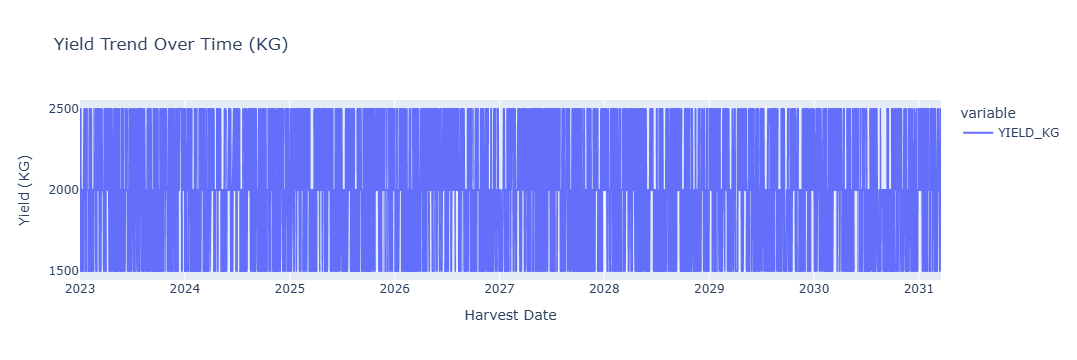

In [18]:
fig2=px.line(pvt_table, title='Yield Trend Over Time (KG)', labels={'HARVEST_DATE':'Harvest Date', 'value':'Yield (KG)'})
fig2.write_image('crop_yield_trend.png')
fig2.show()

In [19]:
pwd

'C:\\Users\\Abid'